# RoadSafe Analytics — Stage 9: DBSCAN Geospatial Clustering

## Objective

This notebook identifies geographical concentrations of road collisions across Great Britain using **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**.

The clustering uses **only latitude and longitude**. Collision severity, casualty counts, and other collision attributes are **not used as DBSCAN input features**.

### Workflow
1. Load `collisions_clean.parquet` from Stage 4.
2. Validate and preprocess latitude/longitude.
3. Explore the geographical collision distribution.
4. Convert coordinates from degrees to radians.
5. Use a k-distance plot to support parameter selection.
6. Compare several `eps` and `min_samples` combinations.
7. Fit a final DBSCAN model using the haversine metric.
8. Evaluate clusters, noise, cluster sizes, and clustered percentage.
9. Visualize and interpret major collision concentrations.
10. Discuss road-safety significance and limitations.

## 1. Import libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")

EARTH_RADIUS_KM = 6371.0088

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the cleaned Stage 4 collision dataset

The notebook searches common project-relative locations so it can run from either the repository root or the `notebooks` directory.

The source dataset is read only; this notebook does not overwrite it.

In [2]:
candidate_paths = [
    Path("data/processed/collisions_clean.parquet"),
    Path("../data/processed/collisions_clean.parquet"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find collisions_clean.parquet. "
        "Expected it under data/processed/."
    )

collisions = pd.read_parquet(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Dataset shape: {collisions.shape}")
print(f"Rows: {len(collisions):,}")
print(f"Columns: {collisions.shape[1]}")

Loaded: ../data/processed/collisions_clean.parquet
Dataset shape: (101525, 44)
Rows: 101,525
Columns: 44


## 3. Inspect coordinate fields

In [3]:
required_columns = {"latitude", "longitude"}
missing_columns = required_columns - set(collisions.columns)

if missing_columns:
    raise KeyError(f"Missing required columns: {sorted(missing_columns)}")

collisions[["latitude", "longitude"]].describe()

,latitude,longitude
count,101523.000000,101523.000000
mean,52.375658,-1.223959
std,1.308239,1.356983
min,49.912530,-7.417720
25%,51.464460,-2.118700
50%,51.888640,-1.138910
75%,53.325860,-0.137910
max,60.345250,1.755590


In [4]:
print("Missing coordinate values:")
print(collisions[["latitude", "longitude"]].isna().sum())

Missing coordinate values:
latitude     2
longitude    2
dtype: int64


## 4. Coordinate preprocessing

Only `latitude` and `longitude` are used for clustering.

Steps:
- select the two coordinate columns;
- convert them to numeric values;
- remove missing coordinates;
- remove coordinates outside Great Britain's approximate geographic bounds;
- convert degrees to radians for haversine distance.

Approximate bounds are used only as a data-quality check, not as DBSCAN features.

In [5]:
geo = collisions[["latitude", "longitude"]].copy()

geo["latitude"] = pd.to_numeric(geo["latitude"], errors="coerce")
geo["longitude"] = pd.to_numeric(geo["longitude"], errors="coerce")

before = len(geo)
geo = geo.dropna(subset=["latitude", "longitude"])

# Broad bounds covering Great Britain and allowing a small margin.
valid_mask = (
    geo["latitude"].between(49.0, 61.5)
    & geo["longitude"].between(-8.5, 2.5)
)
geo = geo.loc[valid_mask].copy()

removed = before - len(geo)

print(f"Original rows: {before:,}")
print(f"Valid coordinate rows: {len(geo):,}")
print(f"Rows removed due to missing/invalid coordinates: {removed:,}")

Original rows: 101,525
Valid coordinate rows: 101,523
Rows removed due to missing/invalid coordinates: 2


## 5. Initial geographical EDA

### Visualization 1 — Collision distribution

Each point represents a recorded collision. Dense urban regions appear as visibly concentrated areas.

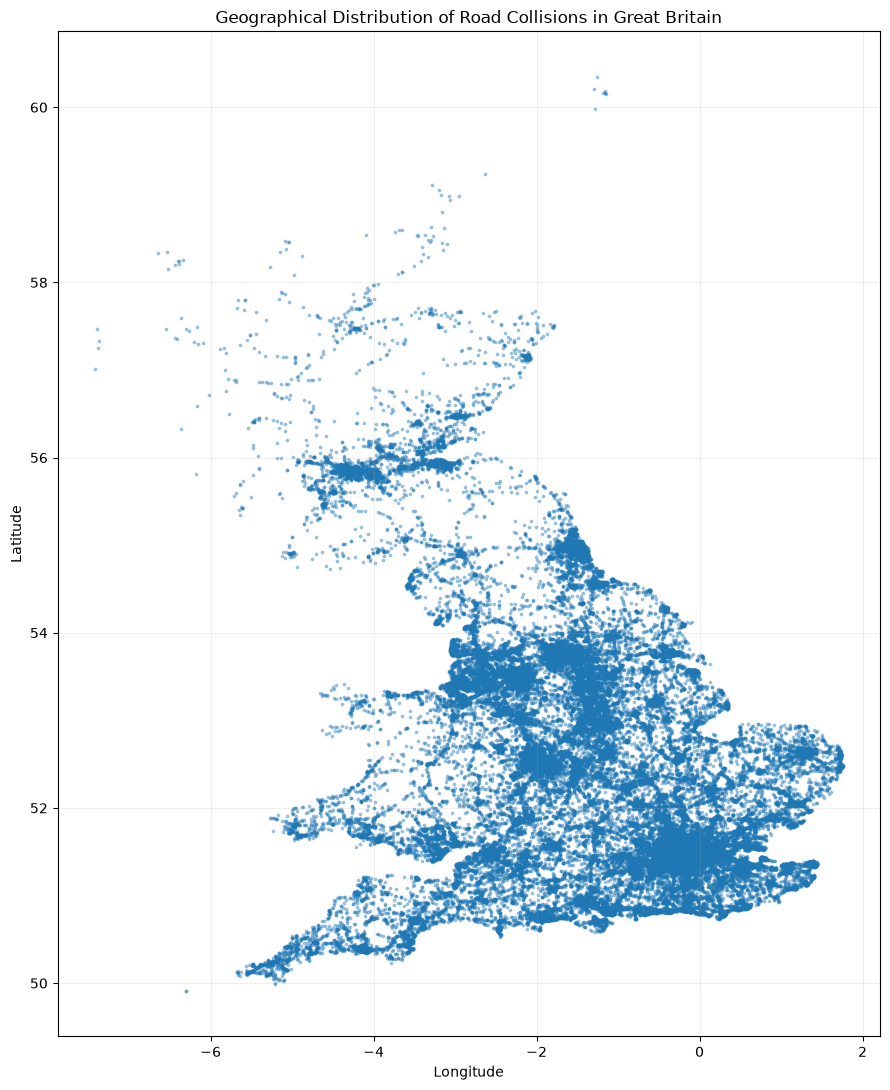

In [6]:
plt.figure(figsize=(9, 11))
plt.scatter(
    geo["longitude"],
    geo["latitude"],
    s=3,
    alpha=0.35
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Road Collisions in Great Britain")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Convert coordinates to radians

Scikit-learn's haversine metric expects latitude and longitude in **radians**.

The coordinate order remains:

`[latitude, longitude]`

In [7]:
coords_deg = geo[["latitude", "longitude"]].to_numpy()
coords_rad = np.radians(coords_deg)

print("Coordinate matrix shape:", coords_rad.shape)
print("Example in degrees:", coords_deg[0])
print("Example in radians:", coords_rad[0])

Coordinate matrix shape: (101523, 2)
Example in degrees: [54.5665 -1.2642]
Example in radians: [ 0.95236509 -0.02206445]


## 7. k-distance analysis

For `min_samples = 10`, the distance to each point's 10th nearest neighbour is calculated.

A sharp increase in the sorted k-distance curve indicates the transition from dense regions toward sparse observations. Because a small number of isolated observations can create very large distances, the main plot is zoomed to 20 km so the useful part of the curve remains visible.

In [8]:
K = 10

# A reproducible sample keeps this diagnostic fast while preserving the
# overall spatial-density pattern.
sample_n = min(25_000, len(coords_rad))
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(coords_rad), size=sample_n, replace=False)
coords_sample = coords_rad[sample_idx]

nn = NearestNeighbors(
    n_neighbors=K,
    metric="haversine",
    algorithm="ball_tree"
)
nn.fit(coords_sample)

distances, _ = nn.kneighbors(coords_sample)

k_distances_km = np.sort(distances[:, -1] * EARTH_RADIUS_KM)

quantiles = [0.50, 0.75, 0.90, 0.95, 0.99]
for q in quantiles:
    print(f"{int(q*100)}% quantile: {np.quantile(k_distances_km, q):.3f} km")

50% quantile: 1.764 km
75% quantile: 3.715 km
90% quantile: 6.767 km
95% quantile: 9.133 km
99% quantile: 17.908 km


### Visualization 2 — 10-distance plot

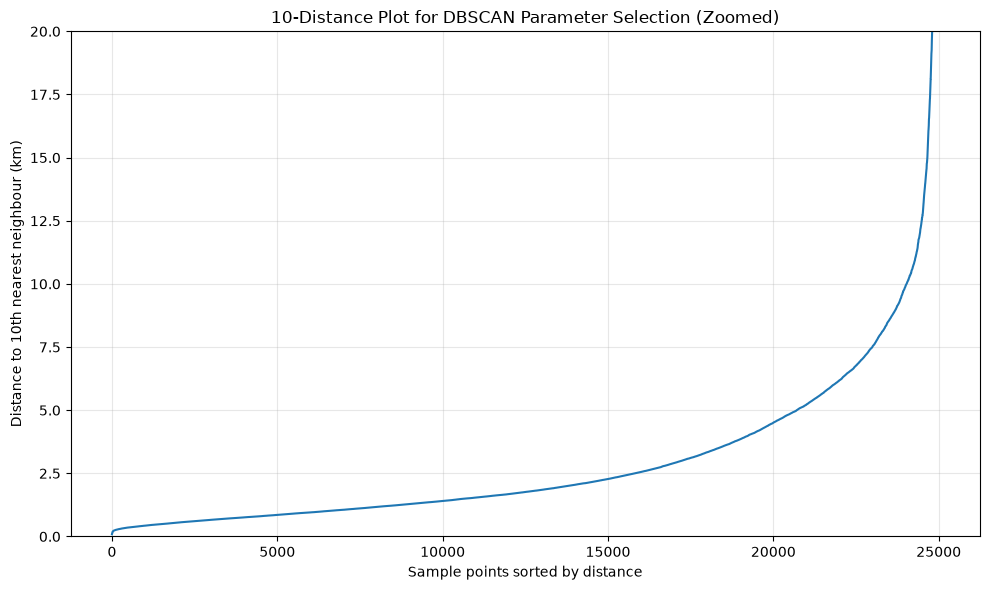

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(k_distances_km)
plt.ylim(0, 20)
plt.xlabel("Sample points sorted by distance")
plt.ylabel("Distance to 10th nearest neighbour (km)")
plt.title("10-Distance Plot for DBSCAN Parameter Selection (Zoomed)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the k-distance plot

The curve rises gradually and then becomes much steeper for sparse observations. There is no single mathematically mandatory `eps`; DBSCAN parameter choice also depends on the spatial scale of the question.

For this project, sub-kilometre radii are tested because the objective is to detect **local collision concentrations**, rather than merge entire towns or neighbouring urban areas into very broad clusters.

## 8. Parameter tuning

Several combinations of:
- `eps`: 0.25, 0.50, 0.75 and 1.00 km
- `min_samples`: 5, 10 and 20

are compared.

For computational efficiency, this tuning experiment uses the same reproducible sample as the k-distance diagnostic. **The final model is fitted and evaluated on the complete cleaned coordinate dataset.**

In [10]:
eps_values_km = [0.25, 0.50, 0.75, 1.00]
min_samples_values = [5, 10, 20]

tuning_rows = []

for min_samples in min_samples_values:
    for eps_km in eps_values_km:
        model = DBSCAN(
            eps=eps_km / EARTH_RADIUS_KM,
            min_samples=min_samples,
            metric="haversine",
            algorithm="ball_tree"
        )
        labels = model.fit_predict(coords_sample)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        clustered = int(np.sum(labels != -1))
        clustered_pct = 100 * clustered / len(labels)

        tuning_rows.append({
            "eps_km": eps_km,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": n_noise,
            "clustered_points": clustered,
            "clustered_pct": clustered_pct
        })

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.round(2)

,eps_km,min_samples,clusters,noise_points,clustered_points,clustered_pct
0,0.25,5,239,22956,2044,8.18
1,0.50,5,505,18096,6904,27.62
2,0.75,5,593,13941,11059,44.24
3,1.00,5,584,10991,14009,56.04
4,0.25,10,19,24739,261,1.04
5,0.50,10,87,22377,2623,10.49
6,0.75,10,144,19205,5795,23.18
7,1.00,10,174,16291,8709,34.84
8,0.25,20,0,25000,0,0.00
9,0.50,20,17,24427,573,2.29


### Visualization 3 — DBSCAN parameter comparison

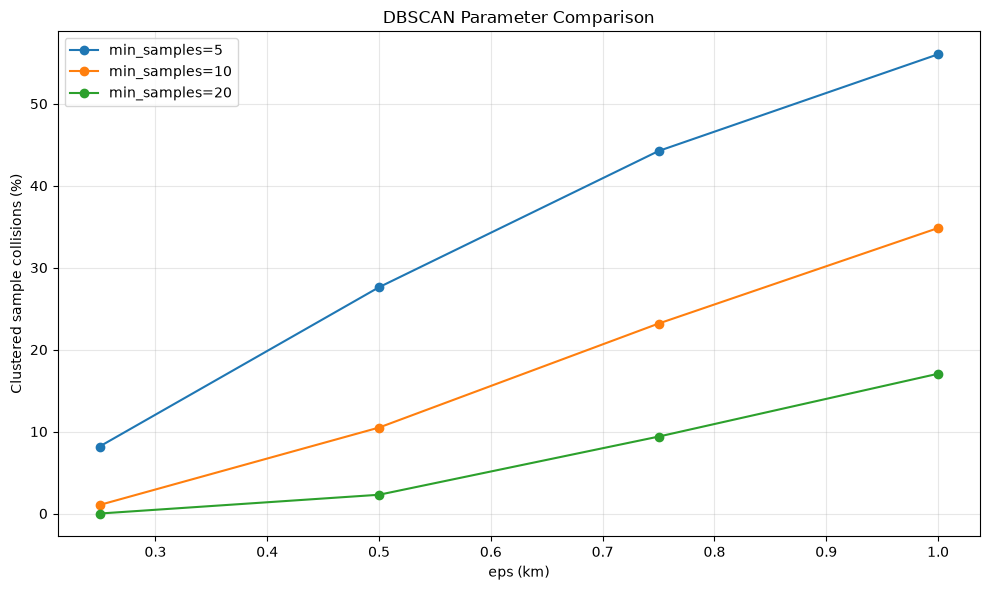

In [11]:
plt.figure(figsize=(10, 6))

for min_samples in min_samples_values:
    subset = tuning_results[
        tuning_results["min_samples"] == min_samples
    ].sort_values("eps_km")

    plt.plot(
        subset["eps_km"],
        subset["clustered_pct"],
        marker="o",
        label=f"min_samples={min_samples}"
    )

plt.xlabel("eps (km)")
plt.ylabel("Clustered sample collisions (%)")
plt.title("DBSCAN Parameter Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Final parameter choice

The final model uses:

- **`eps = 0.50 km`**
- **`min_samples = 10`**

This is intentionally conservative for a local hotspot-style analysis. A collision must lie within a sufficiently dense neighbourhood before it is assigned to a cluster. Larger `eps` values increase the clustered percentage but also increase the risk of connecting nearby concentrations into large continuous clusters. Smaller `min_samples` values make cluster formation easier and may retain weaker concentrations.

The final choice therefore balances local spatial resolution with a meaningful density requirement.

> The tuning graph is based on a reproducible sample for efficiency. The evaluation below is performed on the full dataset, so its clustered percentage is the authoritative final result.

In [12]:
FINAL_EPS_KM = 0.50
FINAL_MIN_SAMPLES = 10

dbscan = DBSCAN(
    eps=FINAL_EPS_KM / EARTH_RADIUS_KM,
    min_samples=FINAL_MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree"
)

geo["cluster"] = dbscan.fit_predict(coords_rad)

print("Final DBSCAN model fitted successfully on the full dataset.")

Final DBSCAN model fitted successfully on the full dataset.


## 10. Evaluation of the final model

In [13]:
noise_mask = geo["cluster"] == -1

n_clusters = geo.loc[~noise_mask, "cluster"].nunique()
n_noise = int(noise_mask.sum())
n_clustered = int((~noise_mask).sum())
clustered_pct = 100 * n_clustered / len(geo)

cluster_sizes = (
    geo.loc[~noise_mask, "cluster"]
    .value_counts()
    .sort_values(ascending=False)
)

print(f"Final eps:             {FINAL_EPS_KM:.2f} km")
print(f"Final min_samples:     {FINAL_MIN_SAMPLES}")
print(f"Number of clusters:    {n_clusters:,}")
print(f"Noise points:          {n_noise:,}")
print(f"Clustered collisions:  {n_clustered:,}")
print(f"Percentage clustered:  {clustered_pct:.2f}%")

if not cluster_sizes.empty:
    print(f"Largest cluster:       {cluster_sizes.iloc[0]:,} collisions")

cluster_sizes.head(10).rename("collision_count").to_frame()

Final eps:             0.50 km
Final min_samples:     10
Number of clusters:    837
Noise points:          59,598
Clustered collisions:  41,925
Percentage clustered:  41.30%
Largest cluster:       15,099 collisions


,collision_count
cluster,
32,15099
24,1524
38,633
5,495
29,423
61,422
20,405
28,405
10,351


### Evaluation interpretation

DBSCAN deliberately labels observations that do not satisfy its local-density requirement as **noise (`-1`)**. Therefore, a substantial noise percentage is not automatically a model failure. In this application, it allows the analysis to distinguish dense geographical concentrations from more isolated collision locations.

## 11. Geographic DBSCAN clusters

### Visualization 4 — DBSCAN cluster map

Noise points are shown faintly in the background. Clustered observations are plotted over them. Because DBSCAN may identify hundreds of clusters, colours repeat; the purpose of this figure is to reveal the spatial pattern of concentrated collision locations rather than provide a unique legend entry for every cluster.

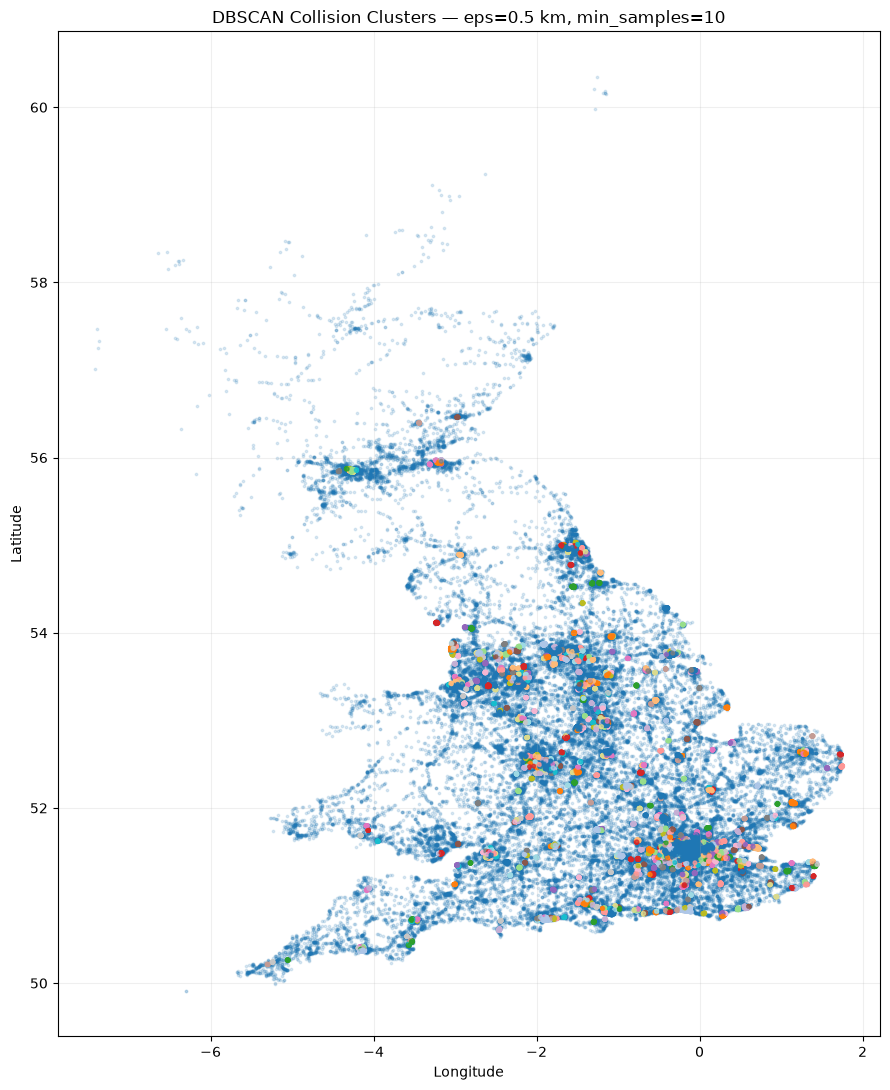

In [14]:
plt.figure(figsize=(9, 11))

noise = geo[geo["cluster"] == -1]
clustered = geo[geo["cluster"] != -1]

plt.scatter(
    noise["longitude"],
    noise["latitude"],
    s=3,
    alpha=0.15,
    label="Noise"
)

plt.scatter(
    clustered["longitude"],
    clustered["latitude"],
    c=clustered["cluster"],
    cmap="tab20",
    s=7,
    alpha=0.75
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    f"DBSCAN Collision Clusters — eps={FINAL_EPS_KM} km, "
    f"min_samples={FINAL_MIN_SAMPLES}"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Cluster-size distribution

DBSCAN cluster sizes can be extremely right-skewed: a major metropolitan concentration can contain far more observations than typical local clusters.

A logarithmic x-axis prevents the largest cluster from compressing all smaller clusters into a narrow part of the figure.

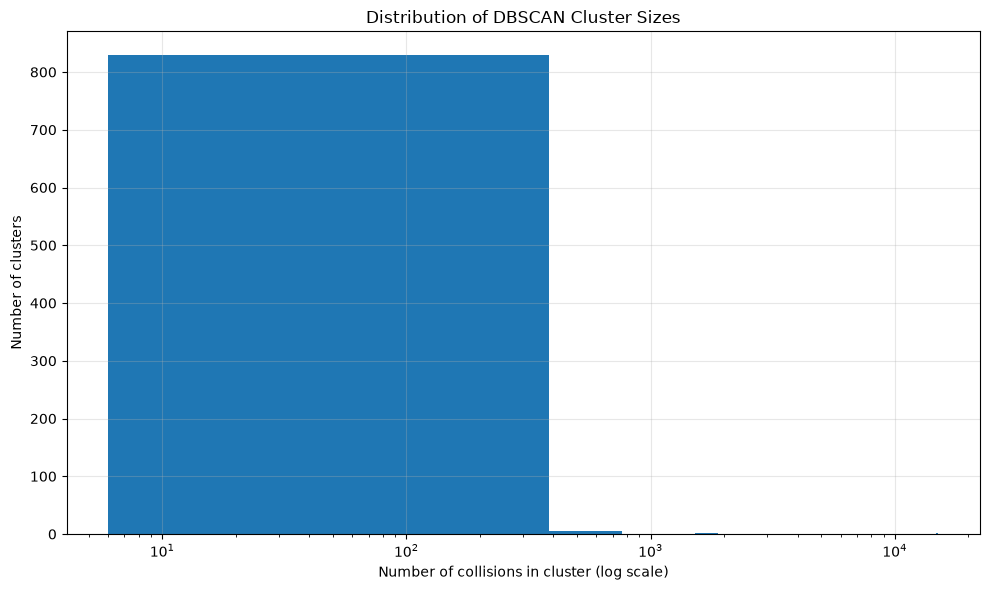

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(cluster_sizes.values, bins=40)
plt.xscale("log")
plt.xlabel("Number of collisions in cluster (log scale)")
plt.ylabel("Number of clusters")
plt.title("Distribution of DBSCAN Cluster Sizes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Major geographical collision concentrations

The table below summarizes the largest clusters using:
- collision count;
- mean latitude;
- mean longitude.

The mean coordinates are approximate cluster centres for interpretation only. They are not used as DBSCAN inputs beyond the original point coordinates.

In [16]:
cluster_summary = (
    geo.loc[geo["cluster"] != -1]
    .groupby("cluster")
    .agg(
        collision_count=("cluster", "size"),
        mean_latitude=("latitude", "mean"),
        mean_longitude=("longitude", "mean")
    )
    .sort_values("collision_count", ascending=False)
)

cluster_summary.head(15).round({
    "mean_latitude": 5,
    "mean_longitude": 5
})

,collision_count,mean_latitude,mean_longitude
cluster,,,
32,15099,51.51305,-0.10623
24,1524,52.48138,-1.88000
38,633,51.49349,-0.39137
5,495,52.95813,-1.16236
29,423,53.80720,-1.54019
61,422,50.83015,-0.15004
20,405,53.40260,-2.95638
28,405,53.79401,-1.76032
10,351,50.80978,-1.07704


## 14. Road-safety interpretation

The DBSCAN results show that recorded road collisions are not uniformly distributed across Great Britain. Instead, they form many local spatial concentrations, with particularly large concentrations visible in major urban and highly connected road-network areas.

These clusters are useful for **screening and prioritisation**. Road-safety analysts could use them to identify areas that deserve closer investigation, such as examination of junction design, road geometry, traffic control, pedestrian facilities, or recurring local collision patterns.

The largest clusters should not automatically be interpreted as the most dangerous places. Their high counts may partly reflect greater population, road density, and traffic exposure.

## 15. Limitations

### Collision density is not the same as collision risk

This is the most important limitation of the analysis.

DBSCAN identifies areas containing **high concentrations of recorded collisions**. It does **not** measure the probability that a road user will be involved in a collision.

A busy urban area may contain many collisions simply because substantially more vehicles, cyclists, and pedestrians travel through it.

A stronger risk analysis would require exposure measures such as:
- traffic volume;
- annual average daily traffic (AADT);
- vehicle-kilometres travelled;
- pedestrian or cyclist flows;
- road length and network density.

Additional limitations include:
- results depend on the chosen `eps` and `min_samples`;
- GPS/coordinate quality can affect spatial clustering;
- DBSCAN uses a single density threshold even though urban and rural densities differ;
- cluster membership does not by itself explain the causes of collisions;
- this analysis uses only geographical coordinates as clustering features, as required.

## 16. Conclusion

This Stage 9 analysis applied DBSCAN with the **haversine distance metric** to cleaned Great Britain road-collision coordinates.

The workflow:
- preserved the Stage 4 source data;
- used only latitude and longitude for clustering;
- converted geographic coordinates to radians;
- explored DBSCAN parameters using k-distance analysis and parameter comparisons;
- fitted the final model to the full cleaned coordinate dataset;
- quantified clusters, noise, clustered percentage, and cluster sizes;
- visualized geographical concentrations;
- interpreted the results while distinguishing collision **density** from collision **risk**.

The final model uses **`eps = 0.50 km` and `min_samples = 10`**, providing a conservative local-density definition suitable for identifying geographical collision concentrations. The identified clusters provide useful targets for further road-safety investigation, but exposure data would be required before making claims about relative accident risk.